# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Faris Arafat
- **Email:** arafatfaris6@gmail.com
- **ID Dicoding:** faris_arafat17

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Kategori produk apa saja yang masuk ke dalam 5 urutan tertinggi dan 5 urutan terendah berdasarkan total pendapatan pada pesanan yang berhasil dikirim, serta berapa persen sumbangan dari 5 kategori teratas tersebut terhadap total pendapatan produk selama periode September 2016 – Agustus 2018?
- **Pertanyaan 2:** Seberapa besar penurunan rata-rata skor ulasan pelanggan (`review_score`) dalam satuan poin maupun persen ketika pesanan datang terlambat dibandingkan yang tepat waktu, dan negara bagian mana yang paling sering mengalami keterlambatan pengiriman selama periode September 2016 – Agustus 2018?

**Keterangan SMART untuk Pertanyaan 1:**
- **Specific**: Fokus mencari "5 kategori produk dengan pendapatan tertinggi dan 5 kategori terendah" pada pesanan yang sudah sampai ke pembeli (*delivered*).
- **Measurable**: Dihitung dari total pendapatan produk dalam mata uang Real Brasil (BRL), jumlah unit yang terjual, dan persentase porsi pendapatannya terhadap total pendapatan keseluruhan.
- **Action-Oriented**: Hasilnya bisa dipakai untuk mengatur prioritas stok barang, menentukan kategori mana yang layak diberi porsi promosi lebih besar, dan mengevaluasi kategori yang penjualannya sangat kecil.
- **Relevant**: Mengetahui kategori penyumbang pendapatan utama sangat penting agar fokus bisnis dan pemasaran lebih tepat sasaran.
- **Time-bound**: Dibatasi pada data pesanan yang terkirim antara **September 2016 hingga Agustus 2018**.

**Keterangan SMART untuk Pertanyaan 2:**
- **Specific**: Fokus melihat pengaruh "keterlambatan pengiriman" (pesanan tiba melewati tanggal estimasi `order_estimated_delivery_date`) terhadap "skor ulasan pelanggan (`review_score`)" serta mencari negara bagian (*state*) yang paling sering terlambat.
- **Measurable**: Diukur dari selisih poin dan persentase penurunan rata-rata `review_score` (skala 1–5), persentase ulasan buruk (skor 1–2), serta persentase keterlambatan di tiap negara bagian.
- **Action-Oriented**: Memberikan dasar bagi tim operasional untuk memperbaiki perhitungan estimasi waktu tiba dan mengevaluasi kinerja kurir di wilayah yang paling sering terlambat.
- **Relevant**: Ketepatan waktu pengiriman berkaitan langsung dengan kepuasan pembeli dan kepercayaan terhadap *marketplace*.
- **Time-bound**: Dibatasi pada data pesanan yang terkirim antara **September 2016 hingga Agustus 2018**.

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='white', context='notebook')
plt.rcParams.update({
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110
})
BLUE, GREY, ORANGE, RED = '#1f5fa8', '#b4b9c0', '#d9730d', '#c0392b'

## Data Wrangling

### Gathering Data

#### Load `orders_df` dan `order_items_df`

In [2]:
DATA_DIR = 'data' if os.path.exists('data/orders_dataset.csv') else 'E-Commerce Public Dataset'

orders_df = pd.read_csv(f'{DATA_DIR}/orders_dataset.csv')
order_items_df = pd.read_csv(f'{DATA_DIR}/order_items_dataset.csv')
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


#### Load `products_df` dan `translation_df`

In [3]:
products_df = pd.read_csv(f'{DATA_DIR}/products_dataset.csv')
translation_df = pd.read_csv(f'{DATA_DIR}/product_category_name_translation.csv')
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


#### Load `customers_df`, `reviews_df`, `payments_df`, dan `sellers_df`

In [4]:
customers_df = pd.read_csv(f'{DATA_DIR}/customers_dataset.csv')
reviews_df = pd.read_csv(f'{DATA_DIR}/order_reviews_dataset.csv')
payments_df = pd.read_csv(f'{DATA_DIR}/order_payments_dataset.csv')
sellers_df = pd.read_csv(f'{DATA_DIR}/sellers_dataset.csv')

pd.DataFrame({
    'Dataset': ['orders_df', 'order_items_df', 'products_df', 'translation_df', 'customers_df', 'reviews_df', 'payments_df', 'sellers_df'],
    'Jumlah Baris': [len(orders_df), len(order_items_df), len(products_df), len(translation_df), len(customers_df), len(reviews_df), len(payments_df), len(sellers_df)],
    'Jumlah Kolom': [orders_df.shape[1], order_items_df.shape[1], products_df.shape[1], translation_df.shape[1], customers_df.shape[1], reviews_df.shape[1], payments_df.shape[1], sellers_df.shape[1]]
})

,Dataset,Jumlah Baris,Jumlah Kolom
0,orders_df,99441,8
1,order_items_df,112650,7
2,products_df,32951,9
3,translation_df,71,2
4,customers_df,99441,5
5,reviews_df,99224,7
6,payments_df,103886,5
7,sellers_df,3095,4


**Insight:**
- Ada 8 tabel yang berhasil dimuat: `orders_df` (99.441 pesanan), `order_items_df` (112.650 baris barang pesanan), `products_df` (32.951 produk), `translation_df` (71 daftar terjemahan nama kategori ke bahasa Inggris), `customers_df` (99.441 data pelanggan), `reviews_df` (99.224 ulasan pembeli), `payments_df` (103.886 catatan pembayaran), dan `sellers_df` (3.095 penjual).
- Tabel `orders_df` menjadi penghubung utama ke tabel lainnya, yaitu melalui kolom `customer_id` untuk data pelanggan dan `order_id` untuk rincian barang, ulasan, serta pembayaran.

### Assessing Data

#### Identifying tipe data dan struktur tabel utama

In [5]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


#### Identifying *missing value* dan *duplicate data* di seluruh tabel

In [6]:
datasets = {
    'orders_df': orders_df,
    'order_items_df': order_items_df,
    'products_df': products_df,
    'translation_df': translation_df,
    'customers_df': customers_df,
    'reviews_df': reviews_df,
    'payments_df': payments_df,
    'sellers_df': sellers_df
}

pd.DataFrame({
    name: {
        'Total Missing Cells': int(df.isna().sum().sum()),
        'Kolom dengan Missing': ', '.join(
            f"{col} ({cnt})" for col, cnt in df.isna().sum().items() if cnt > 0
        ) or '-',
        'Baris Duplikat Penuh': int(df.duplicated().sum())
    }
    for name, df in datasets.items()
}).T

,Total Missing Cells,Kolom dengan Missing,Baris Duplikat Penuh
orders_df,4908,"order_approved_at (160), order_delivered_carri...",0
order_items_df,0,-,0
products_df,2448,"product_category_name (610), product_name_leng...",0
translation_df,0,-,0
customers_df,0,-,0
reviews_df,145903,"review_comment_title (87656), review_comment_m...",0
payments_df,0,-,0
sellers_df,0,-,0


#### Identifying duplikasi kunci (`review_id` & `order_id`), kategori tanpa terjemahan, dan *invalid value*

In [7]:
untranslated_cats = set(products_df['product_category_name'].dropna()) - set(translation_df['product_category_name'])
deliv_temp = orders_df[orders_df['order_status'] == 'delivered'].copy()
for col in ['order_purchase_timestamp', 'order_delivered_carrier_date', 'order_delivered_customer_date']:
    deliv_temp[col] = pd.to_datetime(deliv_temp[col])

carrier_anomaly = (
    (deliv_temp['order_delivered_carrier_date'] < deliv_temp['order_purchase_timestamp']) |
    (deliv_temp['order_delivered_carrier_date'] > deliv_temp['order_delivered_customer_date'])
).sum()

pd.Series({
    'Pesanan delivered tanpa tanggal diterima pelanggan': int(deliv_temp['order_delivered_customer_date'].isna().sum()),
    'Tanggal kurir tidak logis (sebelum waktu beli atau sesudah diterima)': int(carrier_anomaly),
    'Duplikat review_id pada reviews_df': int(reviews_df['review_id'].duplicated().sum()),
    'Duplikat order_id pada reviews_df (pesanan dengan >1 ulasan)': int(reviews_df['order_id'].duplicated().sum()),
    'Produk dengan berat 0 gram (product_weight_g == 0)': int((products_df['product_weight_g'] == 0).sum()),
    'Kategori produk yang belum ada di tabel terjemahan': ', '.join(sorted(untranslated_cats))
})

Pesanan delivered tanpa tanggal diterima pelanggan                                                                      8
Tanggal kurir tidak logis (sebelum waktu beli atau sesudah diterima)                                                  188
Duplikat review_id pada reviews_df                                                                                    814
Duplikat order_id pada reviews_df (pesanan dengan >1 ulasan)                                                          551
Produk dengan berat 0 gram (product_weight_g == 0)                                                                      4
Kategori produk yang belum ada di tabel terjemahan                      pc_gamer, portateis_cozinha_e_preparadores_de_...
dtype: object

#### Identifying *outlier* pada harga, ongkos kirim, dan lama pengiriman

In [8]:
def iqr_summary(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((s < low) | (s > high)).sum()
    return pd.Series({
        'Min': round(s.min(), 2),
        'Median': round(s.median(), 2),
        'Max': round(s.max(), 2),
        'Batas Atas IQR': round(high, 2),
        'Jumlah Outlier': int(outliers),
        'Persen Outlier (%)': round(outliers / len(s) * 100, 2)
    })

deliv_days = (deliv_temp['order_delivered_customer_date'] - deliv_temp['order_purchase_timestamp']).dt.total_seconds() / 86400

pd.DataFrame({
    'price (BRL)': iqr_summary(order_items_df['price']),
    'freight_value (BRL)': iqr_summary(order_items_df['freight_value']),
    'delivery_days (hari)': iqr_summary(deliv_days)
}).T

,Min,Median,Max,Batas Atas IQR,Jumlah Outlier,Persen Outlier (%)
price (BRL),0.85,74.99,6735.00,277.40,8427.0,7.48
freight_value (BRL),0.00,16.26,409.68,33.25,12134.0,10.77
delivery_days (hari),0.53,10.22,209.63,29.15,4896.0,5.08


**Steps to Take:**
- **Mengubah tipe data tanggal**: Mengubah kolom-kolom waktu di `orders_df`, `order_items_df`, dan `reviews_df` dari teks (`object`) menjadi `datetime`.
- **Menangani data kosong (*missing value*)**: Menyaring pesanan yang statusnya sudah selesai dikirim (`order_status == 'delivered'`) dan punya tanggal diterima yang lengkap (ada 8 pesanan `delivered` yang tanggal terimanya kosong sehingga tidak diikutkan). Untuk 610 produk yang tidak punya nama kategori, diberi label `'unknown'`, lalu menambahkan 2 nama kategori yang belum ada di tabel terjemahan (`pc_gamer` dan `portateis_cozinha_e_preparadores_de_alimentos`).
- **Merapikan ulasan ganda pada pesanan yang sama**: Menghapus duplikat `order_id` di `reviews_df` dengan menyimpan ulasan paling baru (`keep='last'`) supaya satu pesanan hanya diwakili oleh satu nilai ulasan.
- **Memperbaiki nilai yang tidak masuk akal (*invalid value*)**: Mengosongkan (`NaT`) 188 tanggal penyerahan ke kurir yang urutannya terbalik (tercatat sebelum barang dibeli atau sesudah barang diterima pembeli), serta mengganti berat 4 produk yang bernilai 0 gram dengan nilai tengah (median) berat produk.
- **Perlakuan terhadap *outlier***: Nilai *outlier* pada harga barang dan lama pengiriman tetap dipertahankan karena memang mencerminkan penjualan barang mahal serta kejadian pengiriman yang terlambat parah di dunia nyata.

**Insight:**
- Dari pemeriksaan data, ditemukan 5 masalah utama: (1) kolom waktu masih bertipe teks (`object`), (2) ada nilai kosong pada tanggal pengiriman, kategori produk, dan tabel terjemahan, (3) ada 551 pesanan yang punya lebih dari satu ulasan di `reviews_df`, (4) ada 4 produk dengan berat 0 gram serta 188 pesanan dengan urutan waktu kurir yang terbalik, dan (5) terdapat *outlier* pada harga barang, ongkos kirim, serta durasi pengiriman.
- Kolom tanggal estimasi (`order_estimated_delivery_date`) semuanya tercatat pada jam `00:00:00` (tengah malam). Oleh karena itu, perhitungan keterlambatan (`delay_days`) perlu dibandingkan berdasarkan tanggal kalender (`.dt.normalize()`) agar paket yang sampai pada hari estimasi di siang atau sore hari tidak salah dihitung sebagai terlambat.

### Cleaning Data

#### Fixing tipe data tanggal, menyaring pesanan terkirim, dan merapikan urutan waktu pengiriman

In [9]:
orders_clean = orders_df.copy()
order_date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in order_date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

order_items_clean = order_items_df.copy()
order_items_clean['shipping_limit_date'] = pd.to_datetime(order_items_clean['shipping_limit_date'])

# Ambil pesanan yang sudah terkirim dan memiliki tanggal sampai di tangan pembeli
orders_clean = orders_clean[
    (orders_clean['order_status'] == 'delivered') &
    (orders_clean['order_delivered_customer_date'].notna())
].copy()

# Kosongkan tanggal kurir jika waktunya tidak logis (sebelum waktu beli atau sesudah diterima pembeli)
invalid_carrier = (
    (orders_clean['order_delivered_carrier_date'] < orders_clean['order_purchase_timestamp']) |
    (orders_clean['order_delivered_carrier_date'] > orders_clean['order_delivered_customer_date'])
)
orders_clean.loc[invalid_carrier, 'order_delivered_carrier_date'] = pd.NaT

# Hitung lama pengiriman dan selisih hari dari tanggal estimasi
orders_clean['delivery_days'] = (
    (orders_clean['order_delivered_customer_date'] - orders_clean['order_purchase_timestamp']).dt.total_seconds() / 86400
).round(2)
orders_clean['delay_days'] = (
    orders_clean['order_delivered_customer_date'].dt.normalize() -
    orders_clean['order_estimated_delivery_date'].dt.normalize()
).dt.days
orders_clean['delivery_status'] = np.where(orders_clean['delay_days'] > 0, 'Terlambat', 'Tepat Waktu')
orders_clean['delay_group'] = pd.cut(
    orders_clean['delay_days'],
    bins=[-1000, 0, 3, 7, 1000],
    labels=['Tepat Waktu (≤0 hari)', 'Terlambat 1–3 hari', 'Terlambat 4–7 hari', 'Terlambat >7 hari']
)
orders_clean['purchase_year'] = orders_clean['order_purchase_timestamp'].dt.year
orders_clean['purchase_month'] = orders_clean['order_purchase_timestamp'].dt.to_period('M').astype(str)

orders_clean[['order_id', 'order_purchase_timestamp', 'delivery_days', 'delay_days', 'delivery_status', 'delay_group']].head()

,order_id,order_purchase_timestamp,delivery_days,delay_days,delivery_status,delay_group
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,8.44,-8,Tepat Waktu,Tepat Waktu (≤0 hari)
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,13.78,-6,Tepat Waktu,Tepat Waktu (≤0 hari)
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,9.39,-18,Tepat Waktu,Tepat Waktu (≤0 hari)
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,13.21,-13,Tepat Waktu,Tepat Waktu (≤0 hari)
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2.87,-10,Tepat Waktu,Tepat Waktu (≤0 hari)


#### Fixing *missing value*, tabel terjemahan kategori, berat produk 0 gram, dan duplikat ulasan

In [10]:
# Tambahkan 2 kategori yang belum masuk ke tabel terjemahan bahasa Inggris
extra_translation = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'kitchen_and_food_preparers_portables']
})
translation_clean = pd.concat([translation_df, extra_translation], ignore_index=True).drop_duplicates('product_category_name')

products_clean = products_df.merge(translation_clean, on='product_category_name', how='left')
products_clean['category'] = products_clean['product_category_name_english'].fillna('unknown')
products_clean.loc[products_clean['product_weight_g'] == 0, 'product_weight_g'] = np.nan
products_clean['product_weight_g'] = products_clean['product_weight_g'].fillna(products_clean['product_weight_g'].median())

# Simpan satu ulasan terbaru untuk setiap order_id supaya tidak dihitung ganda
reviews_clean = reviews_df.copy()
reviews_clean['review_creation_date'] = pd.to_datetime(reviews_clean['review_creation_date'])
reviews_clean['review_answer_timestamp'] = pd.to_datetime(reviews_clean['review_answer_timestamp'])
reviews_clean = reviews_clean.sort_values('review_creation_date').drop_duplicates('order_id', keep='last').copy()
reviews_clean['review_comment_title'] = reviews_clean['review_comment_title'].fillna('no_title')
reviews_clean['review_comment_message'] = reviews_clean['review_comment_message'].fillna('no_message')

pd.Series({
    'Pesanan terkirim bersih (orders_clean)': len(orders_clean),
    'Kategori produk tanpa terjemahan tersisa': int((products_clean['product_category_name'].notna() & (products_clean['category'] == 'unknown')).sum()),
    'Produk dengan berat 0g tersisa': int((products_clean['product_weight_g'] == 0).sum()),
    'Duplikat order_id pada reviews_clean': int(reviews_clean['order_id'].duplicated().sum())
})

Pesanan terkirim bersih (orders_clean)      96470
Kategori produk tanpa terjemahan tersisa        0
Produk dengan berat 0g tersisa                  0
Duplikat order_id pada reviews_clean            0
dtype: int64

**Insight:**
- Setelah dibersihkan, terdapat **96.470 pesanan terkirim yang valid** dari tanggal **15 September 2016 sampai 29 Agustus 2018**.
- Seluruh 73 kategori produk yang memiliki nama asli bahasa Portugis sekarang sudah punya nama bahasa Inggris, 4 produk dengan berat 0 gram sudah diisi dengan nilai median (700 gram), dan setiap pesanan di `reviews_clean` kini hanya memiliki satu baris ulasan.

## Exploratory Data Analysis (EDA)

### Explore gabungan data transaksi dan ringkasan statistik umum

In [11]:
# Gabungkan tabel untuk melihat data di tingkat item barang maupun tingkat pesanan
items_full_df = (
    orders_clean
    .merge(order_items_clean, on='order_id', how='inner')
    .merge(products_clean[['product_id', 'category', 'product_weight_g']], on='product_id', how='left')
    .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
    .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
)
items_full_df['total_item_value'] = items_full_df['price'] + items_full_df['freight_value']

orders_full_df = (
    orders_clean
    .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
    .merge(reviews_clean[['order_id', 'review_score']], on='order_id', how='left')
    .merge(
        items_full_df.groupby('order_id', as_index=False).agg(
            order_revenue=('price', 'sum'),
            order_freight=('freight_value', 'sum'),
            order_gmv=('total_item_value', 'sum'),
            items_count=('order_item_id', 'count')
        ),
        on='order_id',
        how='inner'
    )
)

pd.Series({
    'Periode Transaksi': f"{orders_full_df['order_purchase_timestamp'].min():%Y-%m-%d} s.d. {orders_full_df['order_purchase_timestamp'].max():%Y-%m-%d}",
    'Total Pesanan Terkirim': f"{len(orders_full_df):,}",
    'Total Pelanggan Unik': f"{orders_full_df['customer_unique_id'].nunique():,}",
    'Total Unit Produk Terjual': f"{len(items_full_df):,}",
    'Total Pendapatan Produk (BRL)': f"{items_full_df['price'].sum():,.2f}",
    'Total Nilai Transaksi + Ongkir (BRL)': f"{items_full_df['total_item_value'].sum():,.2f}",
    'Rata-rata Nilai Belanja per Pesanan (BRL)': f"{orders_full_df['order_revenue'].mean():,.2f}",
    'Rata-rata Lama Pengiriman (hari)': f"{orders_full_df['delivery_days'].mean():.2f}",
    'Persentase Pesanan Terlambat (%)': f"{(orders_full_df['delivery_status'] == 'Terlambat').mean() * 100:.2f}%",
    'Rata-rata Skor Ulasan': f"{orders_full_df['review_score'].mean():.2f} / 5.00"
})

Periode Transaksi                            2016-09-15 s.d. 2018-08-29
Total Pesanan Terkirim                                           96,470
Total Pelanggan Unik                                             93,350
Total Unit Produk Terjual                                       110,189
Total Pendapatan Produk (BRL)                             13,220,248.93
Total Nilai Transaksi + Ongkir (BRL)                      15,418,394.83
Rata-rata Nilai Belanja per Pesanan (BRL)                        137.04
Rata-rata Lama Pengiriman (hari)                                  12.56
Persentase Pesanan Terlambat (%)                                  6.77%
Rata-rata Skor Ulasan                                       4.16 / 5.00
dtype: str

### Explore kategori produk dengan pendapatan tertinggi dan terendah (Pertanyaan 1)

In [12]:
category_perf = (
    items_full_df[items_full_df['category'] != 'unknown']
    .groupby('category', as_index=False)
    .agg(
        total_revenue=('price', 'sum'),
        total_gmv=('total_item_value', 'sum'),
        items_sold=('order_item_id', 'count'),
        unique_orders=('order_id', 'nunique'),
        avg_price=('price', 'mean')
    )
    .sort_values('total_revenue', ascending=False)
    .reset_index(drop=True)
)
category_perf['revenue_share_%'] = (category_perf['total_revenue'] / category_perf['total_revenue'].sum() * 100).round(2)
category_perf['cumulative_share_%'] = category_perf['revenue_share_%'].cumsum().round(2)

print(f"Total sumbangan 5 kategori teratas: {category_perf.head(5)['revenue_share_%'].sum():.2f}% dari seluruh pendapatan produk")
pd.concat([
    category_perf.head(5).assign(Kelompok='Top 5 Tertinggi'),
    category_perf.tail(5).assign(Kelompok='Bottom 5 Terendah')
])[['Kelompok', 'category', 'total_revenue', 'items_sold', 'unique_orders', 'avg_price', 'revenue_share_%']].round(2)

Total sumbangan 5 kategori teratas: 40.35% dari seluruh pendapatan produk


,Kelompok,category,total_revenue,items_sold,unique_orders,avg_price,revenue_share_%
0,Top 5 Tertinggi,health_beauty,1233131.72,9465,8647,130.28,9.45
1,Top 5 Tertinggi,watches_gifts,1165898.98,5857,5493,199.06,8.93
2,Top 5 Tertinggi,bed_bath_table,1023434.76,10953,9272,93.44,7.84
3,Top 5 Tertinggi,sports_leisure,954673.55,8430,7529,113.25,7.32
4,Top 5 Tertinggi,computers_accessories,888613.62,7643,6529,116.27,6.81
68,Bottom 5 Terendah,flowers,1110.04,33,29,33.64,0.01
69,Bottom 5 Terendah,home_comfort_2,760.27,30,24,25.34,0.01
70,Bottom 5 Terendah,cds_dvds_musicals,730.00,14,12,52.14,0.01
71,Bottom 5 Terendah,fashion_childrens_clothes,519.95,7,7,74.28,0.00
72,Bottom 5 Terendah,security_and_services,283.29,2,2,141.64,0.00


### Explore pengaruh keterlambatan pengiriman terhadap skor ulasan dan sebaran wilayah (Pertanyaan 2)

In [13]:
reviewed_orders = orders_full_df.dropna(subset=['review_score']).copy()

status_summary = (
    reviewed_orders
    .groupby('delivery_status')
    .agg(
        jumlah_pesanan=('order_id', 'count'),
        rata_rata_skor=('review_score', 'mean'),
        median_skor=('review_score', 'median'),
        persen_skor_rendah_1_2=('review_score', lambda s: (s <= 2).mean() * 100),
        persen_skor_tinggi_4_5=('review_score', lambda s: (s >= 4).mean() * 100)
    )
    .loc[['Tepat Waktu', 'Terlambat']]
    .round(2)
)

delay_group_summary = (
    reviewed_orders
    .groupby('delay_group', observed=True)
    .agg(
        jumlah_pesanan=('order_id', 'count'),
        rata_rata_skor=('review_score', 'mean'),
        persen_skor_rendah_1_2=('review_score', lambda s: (s <= 2).mean() * 100),
        persen_skor_tinggi_4_5=('review_score', lambda s: (s >= 4).mean() * 100)
    )
    .round(2)
)

print("Perbandingan Status Pengiriman:")
print(status_summary)
print("\nPerbandingan Berdasarkan Lama Keterlambatan:")
delay_group_summary

Perbandingan Status Pengiriman:
                 jumlah_pesanan  rata_rata_skor  median_skor  \
delivery_status                                                
Tepat Waktu               89443            4.29          5.0   
Terlambat                  6381            2.27          1.0   

                 persen_skor_rendah_1_2  persen_skor_tinggi_4_5  
delivery_status                                                  
Tepat Waktu                        9.27                   82.66  
Terlambat                         62.40                   26.72  

Perbandingan Berdasarkan Lama Keterlambatan:


,jumlah_pesanan,rata_rata_skor,persen_skor_rendah_1_2,persen_skor_tinggi_4_5
delay_group,,,,
Tepat Waktu (≤0 hari),89443,4.29,9.27,82.66
Terlambat 1–3 hari,1852,3.29,32.13,53.19
Terlambat 4–7 hari,1748,2.10,67.62,22.54
Terlambat >7 hari,2781,1.70,79.29,11.72


In [14]:
state_delivery = (
    reviewed_orders
    .groupby('customer_state', as_index=False)
    .agg(
        total_orders=('order_id', 'count'),
        late_orders=('delivery_status', lambda s: (s == 'Terlambat').sum()),
        late_pct=('delivery_status', lambda s: (s == 'Terlambat').mean() * 100),
        avg_delivery_days=('delivery_days', 'mean'),
        avg_review_score=('review_score', 'mean')
    )
)
# Ambil negara bagian yang punya minimal 500 pesanan supaya perbandingannya adil
major_states_late = state_delivery[state_delivery['total_orders'] >= 500].sort_values('late_pct', ascending=False).reset_index(drop=True)
major_states_late.head(10).round(2)

,customer_state,total_orders,late_orders,late_pct,avg_delivery_days,avg_review_score
0,MA,712,122,17.13,21.44,3.83
1,CE,1273,174,13.67,21.21,3.94
2,RJ,12211,1456,11.92,15.24,3.97
3,BA,3229,384,11.89,19.25,3.93
4,PA,933,100,10.72,23.64,3.91
5,ES,1969,205,10.41,15.61,4.08
6,PB,512,52,10.16,20.25,4.08
7,MS,699,68,9.73,15.63,4.16
8,PE,1579,149,9.44,18.37,4.08
9,SC,3519,284,8.07,14.88,4.13


**Insight:**
- **Pendapatan per Kategori (Pertanyaan 1)**: Dari 73 kategori produk yang diketahui, **5 kategori teratas menyumbang 40,35% dari total pendapatan** (5.265.752,63 BRL dari 13.050.903,31 BRL). Urutannya adalah `health_beauty` (1.233.131,72 BRL; 9,45%), `watches_gifts` (1.165.898,98 BRL; 8,93%), `bed_bath_table` (1.023.434,76 BRL; 7,84%), `sports_leisure` (954.673,55 BRL; 7,32%), dan `computers_accessories` (888.613,62 BRL; 6,81%). Sebaliknya, 5 kategori paling bawah (`security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`, `home_comfort_2`, dan `flowers`) masing-masing hanya menyumbang sekitar 0,01% atau kurang.
- **Dampak Keterlambatan Pengiriman (Pertanyaan 2)**: Pesanan yang tiba **Tepat Waktu** rata-rata mendapat skor ulasan **4,29 dari 5,00** (hanya 9,27% yang memberi skor 1–2). Ketika pesanan **Terlambat**, rata-rata skornya turun **2,02 poin (-47,1%) menjadi 2,27 dari 5,00**, dan persentase pembeli yang memberi skor buruk (1–2) naik drastis menjadi **62,40%**. Semakin lama paket terlambat, skornya makin turun: terlambat 1–3 hari (**3,29**), terlambat 4–7 hari (**2,10**), dan terlambat lebih dari 7 hari (**1,70**).
- **Perbandingan Antar Wilayah**: Untuk negara bagian dengan minimal 500 pesanan, keterlambatan tertinggi terjadi di **MA – Maranhão (17,13%, skor 3,83)**, **CE – Ceará (13,67%, skor 3,94)**, pasar terbesar kedua **RJ – Rio de Janeiro (11,92%, skor 3,97)**, dan **BA – Bahia (11,89%, skor 3,93)**. Angka ini jauh lebih tinggi dibandingkan pusat pengiriman di **SP – São Paulo** yang tingkat keterlambatannya hanya **4,38%** dengan rata-rata skor **4,25**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang masuk ke dalam 5 urutan tertinggi dan 5 urutan terendah berdasarkan total pendapatan pada pesanan yang berhasil dikirim, serta berapa persen sumbangan dari 5 kategori teratas tersebut terhadap total pendapatan produk selama periode September 2016 – Agustus 2018?

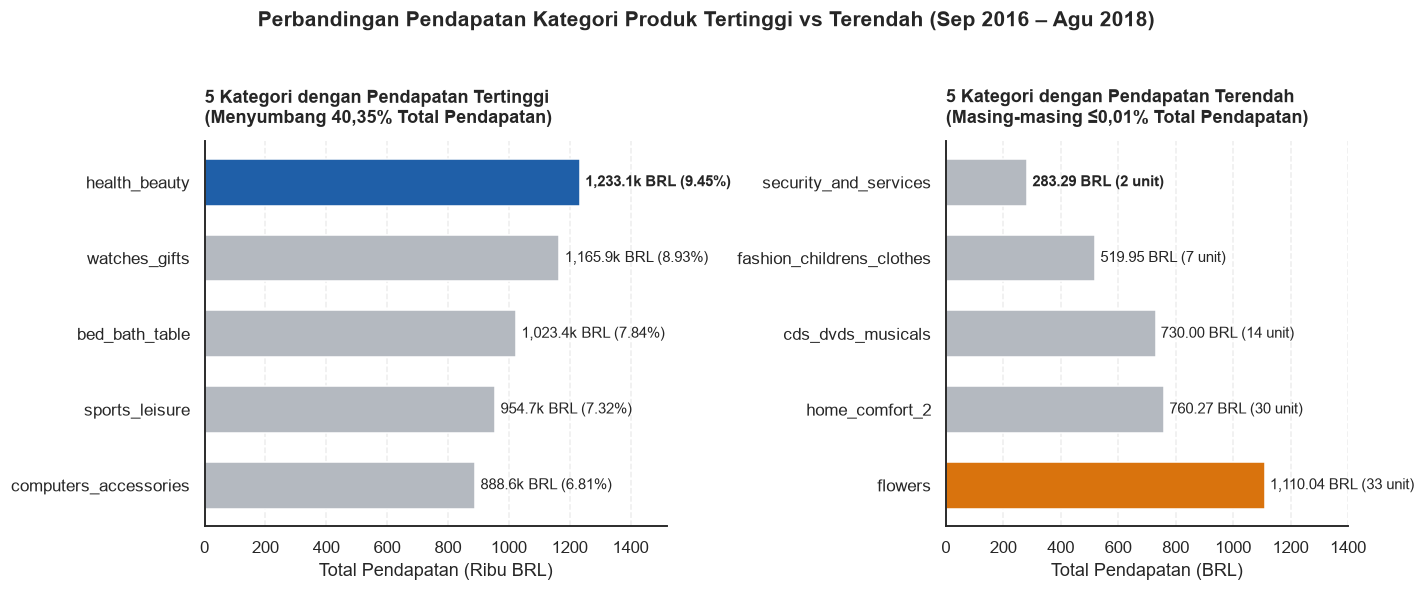

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.15, 1]})

top5 = category_perf.head(5).iloc[::-1]
bot5 = category_perf.tail(5)

# Grafik Kiri: 5 Kategori Tertinggi
colors_top = [GREY if i < 4 else BLUE for i in range(len(top5))]
bars1 = axes[0].barh(top5['category'], top5['total_revenue'] / 1e3, color=colors_top, height=0.62)
axes[0].set_title('5 Kategori dengan Pendapatan Tertinggi\n(Menyumbang 40,35% Total Pendapatan)', fontsize=12, fontweight='bold', loc='left', pad=12)
axes[0].set_xlabel('Total Pendapatan (Ribu BRL)')
axes[0].set_xlim(0, 1520)
axes[0].grid(axis='x', linestyle='--', alpha=0.35)
for bar, (_, row) in zip(bars1, top5.iterrows()):
    w = bar.get_width()
    axes[0].text(w + 18, bar.get_y() + bar.get_height() / 2,
                 f"{w:,.1f}k BRL ({row['revenue_share_%']:.2f}%)",
                 va='center', fontsize=9.5, fontweight='bold' if row['category'] == 'health_beauty' else 'normal')

# Grafik Kanan: 5 Kategori Terendah
colors_bot = [ORANGE if i == 0 else GREY for i in range(len(bot5))]
bars2 = axes[1].barh(bot5['category'], bot5['total_revenue'], color=colors_bot, height=0.62)
axes[1].set_title('5 Kategori dengan Pendapatan Terendah\n(Masing-masing ≤0,01% Total Pendapatan)', fontsize=12, fontweight='bold', loc='left', pad=12)
axes[1].set_xlabel('Total Pendapatan (BRL)')
axes[1].set_xlim(0, 1400)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
for bar, (_, row) in zip(bars2, bot5.iterrows()):
    w = bar.get_width()
    axes[1].text(w + 18, bar.get_y() + bar.get_height() / 2,
                 f"{w:,.2f} BRL ({int(row['items_sold'])} unit)",
                 va='center', fontsize=9.5, fontweight='bold' if row['category'] == 'security_and_services' else 'normal')

plt.suptitle('Perbandingan Pendapatan Kategori Produk Tertinggi vs Terendah (Sep 2016 – Agu 2018)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Seberapa besar penurunan rata-rata skor ulasan pelanggan (`review_score`) dalam satuan poin maupun persen ketika pesanan datang terlambat dibandingkan yang tepat waktu, dan negara bagian mana yang paling sering mengalami keterlambatan pengiriman selama periode September 2016 – Agustus 2018?

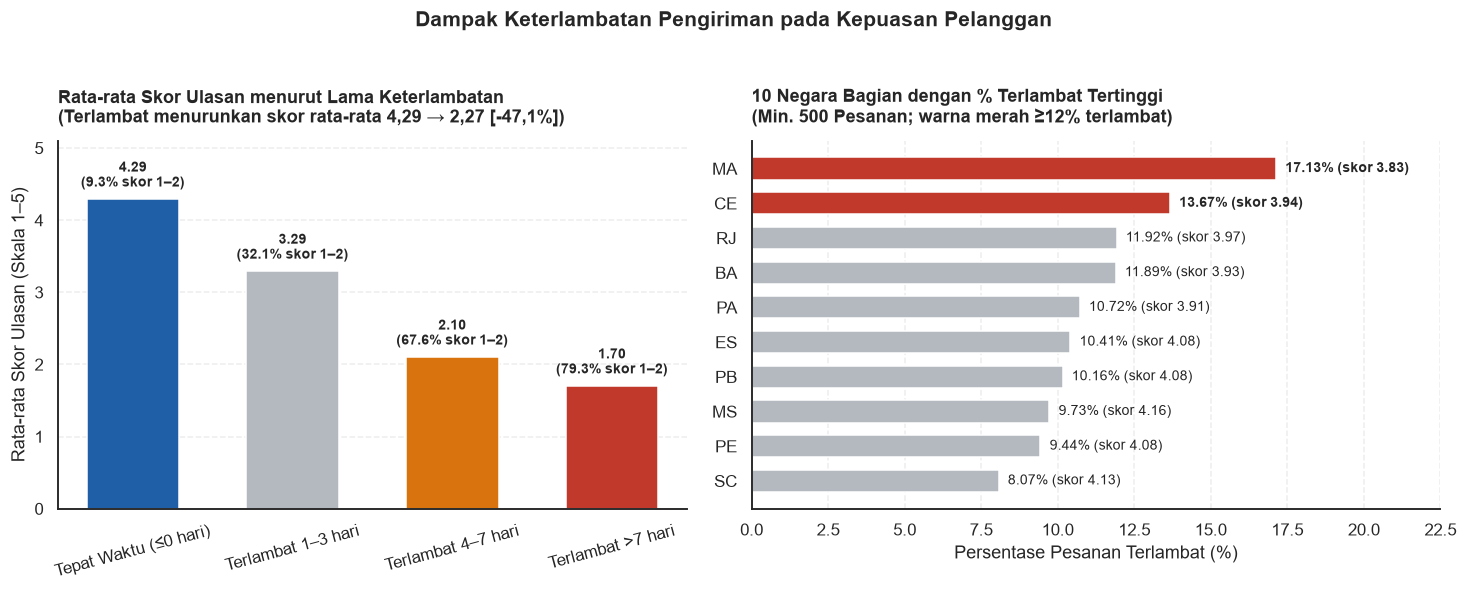

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1.05, 1.15]})

# Grafik Kiri: Rata-rata Skor Ulasan per Lama Keterlambatan
dg = delay_group_summary.reset_index()
bar_colors = [BLUE, GREY, ORANGE, RED]
bars_left = axes[0].bar(dg['delay_group'], dg['rata_rata_skor'], color=bar_colors, width=0.58)
axes[0].set_title('Rata-rata Skor Ulasan menurut Lama Keterlambatan\n(Terlambat menurunkan skor rata-rata 4,29 → 2,27 [-47,1%])',
                  fontsize=11.5, fontweight='bold', loc='left', pad=12)
axes[0].set_ylabel('Rata-rata Skor Ulasan (Skala 1–5)')
axes[0].set_ylim(0, 5.1)
axes[0].grid(axis='y', linestyle='--', alpha=0.35)
axes[0].tick_params(axis='x', rotation=15)

for bar, (_, row) in zip(bars_left, dg.iterrows()):
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 0.12,
                 f"{h:.2f}\n({row['persen_skor_rendah_1_2']:.1f}% skor 1–2)",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Grafik Kanan: 10 Negara Bagian dengan Persentase Terlambat Tertinggi (min. 500 pesanan)
top_late_states = major_states_late.head(10).iloc[::-1]
state_colors = [RED if r['late_pct'] >= 12 else GREY for _, r in top_late_states.iterrows()]
bars_right = axes[1].barh(top_late_states['customer_state'], top_late_states['late_pct'], color=state_colors, height=0.64)
axes[1].set_title('10 Negara Bagian dengan % Terlambat Tertinggi\n(Min. 500 Pesanan; warna merah ≥12% terlambat)',
                  fontsize=11.5, fontweight='bold', loc='left', pad=12)
axes[1].set_xlabel('Persentase Pesanan Terlambat (%)')
axes[1].set_xlim(0, 22.5)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)

for bar, (_, row) in zip(bars_right, top_late_states.iterrows()):
    w = bar.get_width()
    axes[1].text(w + 0.3, bar.get_y() + bar.get_height() / 2,
                 f"{w:.2f}% (skor {row['avg_review_score']:.2f})",
                 va='center', fontsize=9, fontweight='bold' if row['late_pct'] >= 12 else 'normal')

plt.suptitle('Dampak Keterlambatan Pengiriman pada Kepuasan Pelanggan', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
- **Grafik Pertanyaan 1** menunjukkan bahwa pendapatan sangat terkonsentrasi pada beberapa kategori utama. Kategori `health_beauty` (1.233,1 ribu BRL; 9,45%) dan `watches_gifts` (1.165,9 ribu BRL; 8,93%) menempati posisi teratas, dan gabungan 5 kategori terbesar menyumbang **40,35%** dari total pendapatan produk. Sebaliknya, kategori `security_and_services` hanya terjual 2 unit (283,29 BRL).
- **Grafik Pertanyaan 2** memperlihatkan bahwa begitu paket terlambat meskipun baru **1–3 hari**, rata-rata skor ulasan langsung turun satu poin penuh dari **4,29 menjadi 3,29**, dan saat terlambat **lebih dari 7 hari**, skornya jatuh ke **1,70** (79,29% pembeli memberi skor 1–2). Dari sisi wilayah, negara bagian **MA (17,13%)**, **CE (13,67%)**, **RJ (11,92%)**, dan **BA (11,89%)** adalah daerah dengan persentase keterlambatan tertinggi sekaligus memiliki rata-rata skor ulasan di bawah 4,00.

## Analisis Lanjutan (Opsional)

### RFM Analysis & Pengelompokan Pelanggan (*Manual Binning*)
**Tujuan analisis:** Mengelompokkan pelanggan menggunakan pendekatan **RFM (*Recency, Frequency, Monetary*)** berdasarkan `customer_unique_id` serta membagi pelanggan ke dalam beberapa kelompok nilai belanja dan keaktifan (*manual binning*) untuk melihat kelompok mana yang paling banyak menyumbang pendapatan.

In [17]:
ref_date = orders_full_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = (
    orders_full_df
    .groupby('customer_unique_id', as_index=False)
    .agg(
        last_purchase=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'count'),
        monetary=('order_revenue', 'sum')
    )
)
rfm_df['recency'] = (ref_date - rfm_df['last_purchase']).dt.days

rfm_df['recency_tier'] = pd.cut(
    rfm_df['recency'],
    bins=[0, 90, 180, 365, 1000],
    labels=['Aktif (≤90 hari)', 'Hangat (91–180 hari)', 'Dingin (181–365 hari)', 'Churn (>365 hari)']
)
rfm_df['monetary_tier'] = pd.cut(
    rfm_df['monetary'],
    bins=[0, 50, 150, 500, 100000],
    labels=['Low (<50 BRL)', 'Medium (50–150 BRL)', 'High (150–500 BRL)', 'VIP (>500 BRL)']
)
rfm_df['buyer_type'] = np.where(rfm_df['frequency'] > 1, 'Pelanggan Berulang (≥2 pesanan)', 'Pelanggan Sekali Beli (1 pesanan)')

monetary_summary = (
    rfm_df
    .groupby('monetary_tier', observed=True)
    .agg(
        jumlah_pelanggan=('customer_unique_id', 'count'),
        total_pendapatan=('monetary', 'sum'),
        rata_rata_belanja=('monetary', 'mean')
    )
)
monetary_summary['pangsa_pelanggan_%'] = (monetary_summary['jumlah_pelanggan'] / len(rfm_df) * 100).round(2)
monetary_summary['pangsa_pendapatan_%'] = (monetary_summary['total_pendapatan'] / monetary_summary['total_pendapatan'].sum() * 100).round(2)
monetary_summary.round(2)

,jumlah_pelanggan,total_pendapatan,rata_rata_belanja,pangsa_pelanggan_%,pangsa_pendapatan_%
monetary_tier,,,,,
Low (<50 BRL),27294,874731.66,32.05,29.24,6.62
Medium (50–150 BRL),42385,4027880.75,95.03,45.40,30.47
High (150–500 BRL),20060,4954015.80,246.96,21.49,37.47
VIP (>500 BRL),3611,3363620.72,931.49,3.87,25.44


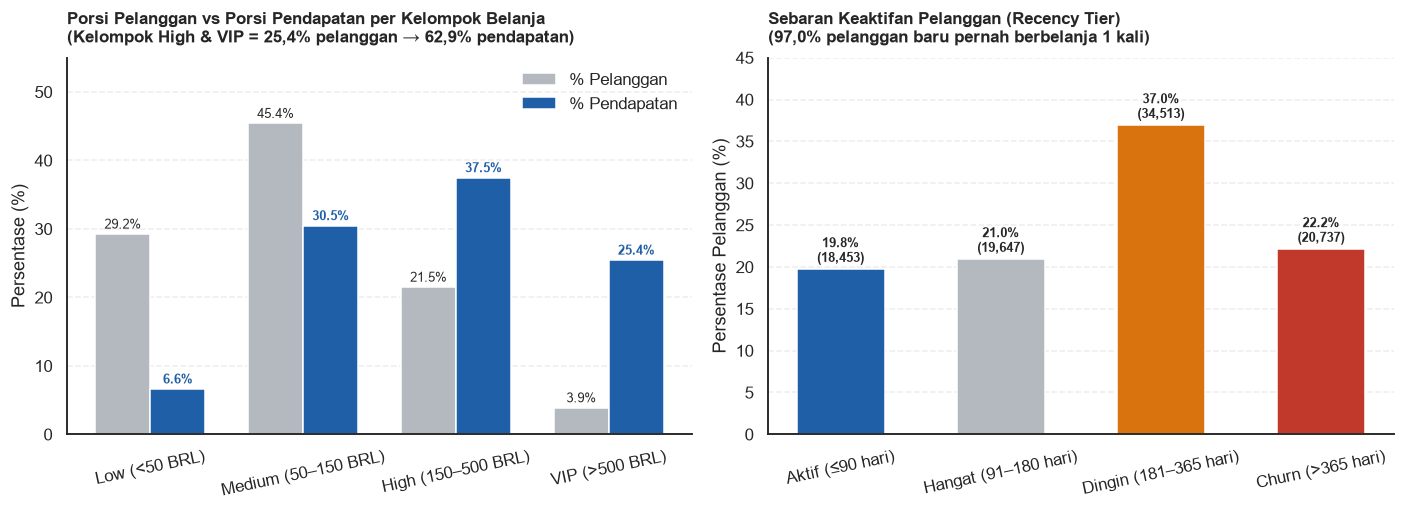

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Grafik Kiri: Perbandingan Porsi Pelanggan vs Porsi Pendapatan per Kelompok Belanja
tiers = monetary_summary.index.astype(str)
x = np.arange(len(tiers))
w = 0.36
b1 = axes[0].bar(x - w/2, monetary_summary['pangsa_pelanggan_%'], width=w, color=GREY, label='% Pelanggan')
b2 = axes[0].bar(x + w/2, monetary_summary['pangsa_pendapatan_%'], width=w, color=BLUE, label='% Pendapatan')
axes[0].set_xticks(x)
axes[0].set_xticklabels(tiers, rotation=12)
axes[0].set_ylabel('Persentase (%)')
axes[0].set_ylim(0, 55)
axes[0].set_title('Porsi Pelanggan vs Porsi Pendapatan per Kelompok Belanja\n(Kelompok High & VIP = 25,4% pelanggan → 62,9% pendapatan)',
                  fontsize=11, fontweight='bold', loc='left', pad=10)
axes[0].legend(frameon=False)
axes[0].grid(axis='y', linestyle='--', alpha=0.35)

for bar in b1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}%", ha='center', fontsize=8.5)
for bar in b2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f"{bar.get_height():.1f}%", ha='center', fontsize=8.5, fontweight='bold', color=BLUE)

# Grafik Kanan: Sebaran Pelanggan berdasarkan Terakhir Kali Berbelanja (Recency)
rec_counts = rfm_df['recency_tier'].value_counts().reindex(
    ['Aktif (≤90 hari)', 'Hangat (91–180 hari)', 'Dingin (181–365 hari)', 'Churn (>365 hari)']
)
rec_pct = (rec_counts / len(rfm_df) * 100).round(1)
r_colors = [BLUE, GREY, ORANGE, RED]
bars_r = axes[1].bar(rec_pct.index.astype(str), rec_pct.values, color=r_colors, width=0.55)
axes[1].set_ylabel('Persentase Pelanggan (%)')
axes[1].set_ylim(0, 45)
axes[1].tick_params(axis='x', rotation=12)
axes[1].set_title('Sebaran Keaktifan Pelanggan (Recency Tier)\n(97,0% pelanggan baru pernah berbelanja 1 kali)',
                  fontsize=11, fontweight='bold', loc='left', pad=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.35)

for bar, cnt in zip(bars_r, rec_counts.values):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%\n({cnt:,})", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

#### Menyimpan data bersih untuk kebutuhan dashboard Streamlit

In [19]:
os.makedirs('dashboard', exist_ok=True)

main_dashboard_df = items_full_df[[
    'order_id', 'customer_unique_id', 'order_purchase_timestamp',
    'delivery_days', 'delay_days', 'delivery_status', 'delay_group',
    'customer_state', 'category', 'price', 'freight_value', 'review_score'
]].copy()
main_dashboard_df['order_purchase_date'] = main_dashboard_df['order_purchase_timestamp'].dt.strftime('%Y-%m-%d')
main_dashboard_df = main_dashboard_df.drop(columns=['order_purchase_timestamp'])

main_dashboard_df.to_csv('dashboard/main_data.csv', index=False)
print(f"main_data.csv berhasil disimpan: {len(main_dashboard_df):,} baris ({os.path.getsize('dashboard/main_data.csv') / (1024*1024):.2f} MB)")

main_data.csv berhasil disimpan: 110,189 baris (16.27 MB)


**Insight:**
- Dari **93.350 pelanggan unik**, sebanyak **97,00%** (90.549 orang) baru berbelanja satu kali, sedangkan pelanggan yang berbelanja lebih dari sekali hanya **3,00%** (2.801 orang).
- Jika dilihat dari total nilai belanjanya (**Monetary Tier**), pelanggan di kelompok **High (150–500 BRL)** dan **VIP (>500 BRL)** jumlahnya hanya **25,36%** dari seluruh pelanggan (23.671 orang), namun menyumbang **62,92% dari total pendapatan** (8,32 juta BRL dari 13,22 juta BRL).
- Dari sisi waktu terakhir berbelanja (**Recency Tier**), sekitar **59,19%** pelanggan sudah tidak bertransaksi selama lebih dari 6 bulan (kelompok *Dingin* 36,97% dan *Churn* 22,21%), sehingga program promosi untuk menarik pelanggan berbelanja kembali sangat dibutuhkan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama periode **September 2016 – Agustus 2018**, 5 kategori produk dengan pendapatan tertinggi pada pesanan terkirim adalah **`health_beauty` (1.233.131,72 BRL; 9,45%)**, **`watches_gifts` (1.165.898,98 BRL; 8,93%)**, **`bed_bath_table` (1.023.434,76 BRL; 7,84%)**, **`sports_leisure` (954.673,55 BRL; 7,32%)**, dan **`computers_accessories` (888.613,62 BRL; 6,81%)**. Kelima kategori ini menyumbang **40,35%** dari total pendapatan produk yang kategorinya teridentifikasi (5,27 juta BRL dari 13,05 juta BRL). Sementara itu, 5 kategori dengan pendapatan terendah adalah **`security_and_services` (283,29 BRL)**, **`fashion_childrens_clothes` (519,95 BRL)**, **`cds_dvds_musicals` (730,00 BRL)**, **`home_comfort_2` (760,27 BRL)**, dan **`flowers` (1.110,04 BRL)** yang masing-masing hanya menyumbang sekitar 0,01% atau kurang.
- **Conclusion pertanyaan 2:** Keterlambatan pengiriman sangat memengaruhi tingkat kepuasan pelanggan selama **September 2016 – Agustus 2018**. Rata-rata `review_score` turun sebesar **2,02 poin atau -47,1%**, dari **4,29 / 5,00** pada pengiriman **Tepat Waktu** (9,27% skor 1–2) menjadi **2,27 / 5,00** pada pengiriman **Terlambat** (62,40% skor 1–2), dan makin turun hingga **1,70 / 5,00** jika terlambat lebih dari 7 hari. Untuk negara bagian dengan minimal 500 pesanan, persentase keterlambatan tertinggi terjadi di **Maranhão / MA (17,13%; skor 3,83)**, **Ceará / CE (13,67%; skor 3,94)**, **Rio de Janeiro / RJ (11,92%; skor 3,97)**, dan **Bahia / BA (11,89%; skor 3,93)**.

**Rekomendasi Action Item:**
- **Perbaikan Pengiriman di Wilayah Rawan Terlambat & Penyesuaian Estimasi Waktu Tiba:** Mengevaluasi kerja sama dengan mitra kurir lokal di jalur pengiriman menuju **MA, CE, RJ, dan BA** agar tingkat keterlambatan yang masih mendekati atau di atas 12% bisa ditekan mendekati rata-rata nasional (6,5%), sekaligus menyesuaikan ulang perhitungan tanggal estimasi tiba (`order_estimated_delivery_date`) dan memberikan kompensasi voucher otomatis jika pesanan terlambat.
- **Menjaga Ketersediaan Stok dan Fokus Promosi pada 5 Kategori Utama:** Memastikan stok barang selalu aman dan menempatkan promosi utama pada 5 kategori penyumbang **40,35% pendapatan** (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`), serta membuat paket *bundling* untuk membantu penjualan kategori yang kurang diminati.
- **Program Diskon Pembelian Kedua untuk Meningkatkan Retensi Pelanggan:** Karena **97,00%** pelanggan baru berbelanja satu kali sedangkan kelompok belanja **High & VIP (≥150 BRL)** menyumbang **62,92% pendapatan**, perusahaan sebaiknya mengirimkan penawaran diskon atau gratis ongkir untuk pembelian kedua dalam 30–60 hari setelah transaksi pertama selesai.